<a href="https://colab.research.google.com/github/ilyassboudrioua/qr-shield-mlops/blob/main/notebooks/03_fichiers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module fichiers
## Étape F.1 : Téléchargement d'EMBER2024 (programmes Windows .NET)

EMBER2024 (2025) décrit 3,2 millions de fichiers par des caractéristiques déjà extraites (aucun vrai fichier n'est téléchargé).
Win32 et Win64 dépassent les ressources de Colab gratuit : on utilise les programmes Windows .NET
(260 000 fichiers d'entraînement, 60 000 de test) et le "challenge set" de malwares évasifs.
Découpage par date fourni par le dataset : entraînement = 52 premières semaines, test = 12 dernières.

Les données sont téléchargées sur le disque de Colab (/content), pas sur le Drive, car elles sont trop lourdes.

In [1]:
# Installer la version corrigée d'oscrypto (correctif disponible sur GitHub)
!pip install -q --force-reinstall --no-deps "oscrypto @ git+https://github.com/wbond/oscrypto.git@d5f3437ed24257895ae1edd9e503cfb352e635a8"

In [2]:
# Installer la version de signify compatible avec thrember
!pip install -q "signify==0.7.1"

In [3]:
# 1. Installer la bibliothèque officielle d'EMBER2024 (thrember)
!pip install -q git+https://github.com/FutureComputing4AI/EMBER2024.git

import thrember, os

# 2. Télécharger les fichiers .NET (entraînement + test) et le challenge set
EMBER_DIR = "/content/ember"
os.makedirs(EMBER_DIR, exist_ok=True)
thrember.download_dataset(EMBER_DIR, split="train", file_type="Dot_Net")
thrember.download_dataset(EMBER_DIR, split="test", file_type="Dot_Net")
thrember.download_dataset(EMBER_DIR, split="challenge")
os.chdir("/content")

# 3. Voir ce qui a été téléchargé
fichiers = sorted(f for f in os.listdir(EMBER_DIR) if f.endswith(".jsonl"))
print("Nombre de fichiers .jsonl :", len(fichiers))
print("Exemples de noms :", fichiers[:3], "...", fichiers[-3:])
taille = sum(os.path.getsize(os.path.join(EMBER_DIR, f)) for f in fichiers) / 1e9
print(f"Taille totale : {taille:.2f} Go")

# 4. Compter les fichiers décrits dans chaque partie
for partie in ["train", "test", "challenge"]:
    chemins = thrember.model.gather_feature_paths(EMBER_DIR, partie)
    n = sum(1 for p in chemins for _ in open(p))
    print(f"{partie:10s} : {n:,} fichiers décrits")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Dot_Net_train.zip: reconstructing file:   0%|          |  0.00B /  937MB            

Dot_Net_train.zip: downloading bytes:           |  0.00B            

Unzipping...


Dot_Net_test.zip: reconstructing file:   0%|          |  0.00B /  220MB            

Dot_Net_test.zip: downloading bytes:           |  0.00B            

Unzipping...


challenge.zip: reconstructing file:   0%|          |  0.00B / 32.1MB            

challenge.zip: downloading bytes:           |  0.00B            

Nombre de fichiers .jsonl : 128
Exemples de noms : ['2023-09-24_2023-09-30_Dot_Net_train.jsonl', '2023-09-24_2023-09-30_challenge_malicious.jsonl', '2023-10-01_2023-10-07_Dot_Net_train.jsonl'] ... ['2024-12-01_2024-12-07_challenge_malicious.jsonl', '2024-12-08_2024-12-14_Dot_Net_test.jsonl', '2024-12-08_2024-12-14_challenge_malicious.jsonl']
Taille totale : 5.71 Go
train      : 520,000 fichiers décrits
test       : 120,000 fichiers décrits
challenge  : 6,315 fichiers décrits


## Étape F.2 : Échantillonnage

520 000 fichiers d'entraînement, c'est trop pour la mémoire de Colab gratuit (plus de 5 Go une fois transformés en nombres).
On tire au hasard un nombre fixe de fichiers dans chaque semaine, pour garder toutes les périodes :
environ 100 000 fichiers pour l'entraînement et 30 000 pour le test.
Le challenge set contient tous les types de fichiers : on ne garde que les programmes .NET, comme notre modèle.
Les fichiers sont lus comme du texte (des caractéristiques), jamais exécutés.

In [4]:
import json, random, collections
import pandas as pd

SRC = "/content/ember"            # données complètes
ECH = "/content/ember_ech"        # échantillon
os.makedirs(ECH, exist_ok=True)
random.seed(42)

def echantillonner(nom_fichier, n):
    lignes = open(os.path.join(SRC, nom_fichier)).readlines()
    choix = random.sample(lignes, min(n, len(lignes)))
    with open(os.path.join(ECH, nom_fichier), "w") as f:
        f.writelines(choix)
    return choix

fichiers_train = [f for f in fichiers if "Dot_Net_train" in f]
fichiers_test = [f for f in fichiers if "Dot_Net_test" in f]
n_train = 100_000 // len(fichiers_train) + 1
n_test = 30_000 // len(fichiers_test) + 1
print(f"Semaines d'entraînement : {len(fichiers_train)} -> {n_train} fichiers par semaine")
print(f"Semaines de test : {len(fichiers_test)} -> {n_test} fichiers par semaine")

meta = []
for nom, n, partie in [(f, n_train, "train") for f in fichiers_train] + [(f, n_test, "test") for f in fichiers_test]:
    for ligne in echantillonner(nom, n):
        d = json.loads(ligne)
        meta.append({"partie": partie, "label": d.get("label"), "file_type": d.get("file_type"),
                     "date": d.get("first_submission_date")})
meta = pd.DataFrame(meta)
type_net = meta["file_type"].mode()[0]

# Challenge set : garder seulement le même type de fichier que l'entraînement
chal = [l for f in fichiers if "challenge" in f for l in open(os.path.join(SRC, f))]
chal_net = [l for l in chal if json.loads(l).get("file_type") == type_net]
with open(os.path.join(ECH, "challenge_dotnet.jsonl"), "w") as f:
    f.writelines(chal_net)

# Résumé
meta["date"] = pd.to_datetime(meta["date"], unit="s")
print(f"\nType de fichier : {type_net}")
print(meta.groupby("partie").agg(fichiers=("label", "size"), debut=("date", "min"), fin=("date", "max")))
print("\nLabels (1 = malveillant, 0 = sûr, None = sans label) :")
print(meta.groupby("partie")["label"].value_counts(dropna=False).unstack())
print("\nChallenge set :", len(chal), "fichiers au total, dont", len(chal_net), "de type", type_net)
print("Types dans le challenge set :", dict(collections.Counter(json.loads(l).get("file_type") for l in chal)))

Semaines d'entraînement : 52 -> 1924 fichiers par semaine
Semaines de test : 12 -> 2501 fichiers par semaine

Type de fichier : Dot_Net
        fichiers               debut                 fin
partie                                                  
test       30012 2024-09-22 00:02:23 2024-12-14 23:54:17
train     100048 2023-09-24 00:05:30 2024-09-21 23:49:52

Labels (1 = malveillant, 0 = sûr, None = sans label) :
label       0      1
partie              
test    14966  15046
train   50110  49938

Challenge set : 6315 fichiers au total, dont 829 de type Dot_Net
Types dans le challenge set : {'Win32': 3225, 'ELF': 386, 'PDF': 805, 'Win64': 814, 'Dot_Net': 829, 'APK': 256}


## Étape F.3 : Vectorisation et vérification des données

Chaque fichier est décrit en texte (JSON) : en-têtes, sections, fonctions importées, statistiques sur les octets, chaînes de caractères…
La bibliothèque officielle thrember transforme chaque description en un vecteur de 2 568 nombres (les features).
On vérifie ensuite les données, comme pour les autres modules : doublons, fuite entre entraînement et test, valeurs manquantes, colonnes constantes.
Les vecteurs sont copiés dans le Drive pour ne pas avoir à refaire ce calcul.

In [7]:
import numpy as np, shutil

# 1. Transformer les descriptions en vecteurs (2 568 features par fichier)
thrember.create_vectorized_features(ECH)
os.chdir("/content")

X_train, y_train = thrember.read_vectorized_features(ECH, subset="train")
X_test, y_test = thrember.read_vectorized_features(ECH, subset="test")
X_chal, y_chal = thrember.read_vectorized_features(ECH, subset="challenge")
print("Entraînement :", X_train.shape, "| Test :", X_test.shape, "| Challenge :", X_chal.shape)

# 2. Vérifications des données
def empreintes(partie):
    return [json.loads(l)["sha256"] for f in sorted(os.listdir(ECH))
            if f.endswith(".jsonl") and partie in f for l in open(os.path.join(ECH, f))]
sha_train, sha_test = empreintes("train"), empreintes("test")
print("\nDoublons dans l'entraînement :", len(sha_train) - len(set(sha_train)))
print("Même fichier dans l'entraînement ET le test (fuite) :", len(set(sha_train) & set(sha_test)))
print("Valeurs manquantes ou infinies :", int((~np.isfinite(X_train)).sum()))
constantes = (X_train.std(axis=0) == 0)
print("Colonnes constantes :", int(constantes.sum()), "sur", X_train.shape[1])
print("Labels entraînement :", dict(zip(*np.unique(y_train, return_counts=True))))

# 3. Copier les vecteurs dans le Drive (pour ne pas recalculer)
DEST = f"{DATA}/fichiers"
os.makedirs(DEST, exist_ok=True)
for f in os.listdir(ECH):
    if f.endswith(".dat"):
        shutil.copy(os.path.join(ECH, f), DEST)
print("\nVecteurs copiés dans le Drive :", sorted(f for f in os.listdir(DEST) if f.endswith(".dat")))

Preparing to vectorize raw features
Vectorizing training set


100%|██████████| 100048/100048 [02:38<00:00, 632.18it/s]


Vectorizing test set


100%|██████████| 30012/30012 [00:46<00:00, 641.19it/s]


Vectorizing challenge set


100%|██████████| 829/829 [00:02<00:00, 384.54it/s]


Entraînement : (100048, 2568) | Test : (30012, 2568) | Challenge : (829, 2568)

Doublons dans l'entraînement : 9622
Même fichier dans l'entraînement ET le test (fuite) : 0
Valeurs manquantes ou infinies : 0
Colonnes constantes : 300 sur 2568
Labels entraînement : {np.int32(0): np.int64(50110), np.int32(1): np.int64(49938)}

Vecteurs copiés dans le Drive : ['X_challenge.dat', 'X_test.dat', 'X_train.dat', 'y_challenge.dat', 'y_test.dat', 'y_train.dat']


## Étape F.3 (suite) : Suppression des doublons et sauvegarde

9 622 fichiers apparaissent plusieurs fois dans l'entraînement (le même fichier présent dans plusieurs semaines).
On vérifie qu'une même empreinte n'a pas deux labels différents, puis on garde une seule copie de chaque fichier.
Les vecteurs et la liste des lignes conservées sont sauvegardés dans le Drive.

In [8]:
from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/QR-Shield/data'
MODELS = '/content/drive/MyDrive/QR-Shield/models'

# 1. Labels contradictoires : même empreinte, labels différents ?
df_sha = pd.DataFrame({"sha": sha_train, "label": y_train})
conflits = df_sha.groupby("sha")["label"].nunique()
print("Empreintes avec deux labels différents :", int((conflits > 1).sum()))

# 2. Garder la première copie de chaque fichier
garder = ~df_sha["sha"].duplicated(keep="first").values
X_train, y_train = X_train[garder], y_train[garder]
print("Entraînement après suppression des doublons :", X_train.shape)
print("Labels :", dict(zip(*np.unique(y_train, return_counts=True))))

# 3. Sauvegarder dans le Drive
DEST = f"{DATA}/fichiers"
os.makedirs(DEST, exist_ok=True)
for f in os.listdir(ECH):
    if f.endswith(".dat"):
        shutil.copy(os.path.join(ECH, f), DEST)
np.save(f"{DEST}/train_garder.npy", garder)
print("\nSauvegardé dans le Drive :", sorted(os.listdir(DEST)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Empreintes avec deux labels différents : 0
Entraînement après suppression des doublons : (90426, 2568)
Labels : {np.int32(0): np.int64(45261), np.int32(1): np.int64(45165)}

Sauvegardé dans le Drive : ['X_challenge.dat', 'X_test.dat', 'X_train.dat', 'train_garder.npy', 'y_challenge.dat', 'y_test.dat', 'y_train.dat']


## Étape F.4 : Baseline et LightGBM

Comme pour les autres modules : d'abord une baseline simple (régression logistique), puis le modèle principal.
Modèle principal : LightGBM, le modèle utilisé par les auteurs d'EMBER. Comme XGBoost, il combine des centaines
de petits arbres de décision, mais il est plus rapide sur beaucoup de features (ici 2 568).

Pour respecter les 3 ensembles du cours, on découpe l'entraînement par date :
les 80 % les plus anciens pour apprendre, les 20 % les plus récents pour la validation (choix du seuil à l'étape suivante).
Le test n'est pas touché.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, recall_score, precision_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score)
import lightgbm as lgb

def evaluer(nom, y, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"Modèle": nom, "TP": tp, "FN": fn, "FP": fp, "TN": tn, "Recall": recall_score(y, pred),
            "Precision": precision_score(y, pred), "F1": f1_score(y, pred), "FPR": fp / (fp + tn),
            "MCC": matthews_corrcoef(y, pred), "ROC-AUC": roc_auc_score(y, proba),
            "PR-AUC": average_precision_score(y, proba)}

# 1. Date de chaque fichier d'entraînement (même ordre que X_train), puis doublons retirés
dates = np.array([json.loads(l)["first_submission_date"] for f in sorted(os.listdir(ECH))
                  if f.endswith(".jsonl") and "train" in f for l in open(os.path.join(ECH, f))])[garder]

# 2. Découpage par date : 80 % les plus anciens / 20 % les plus récents
coupure = np.quantile(dates, 0.8)
est_val = dates > coupure
X_tr, y_tr, X_val, y_val = X_train[~est_val], y_train[~est_val], X_train[est_val], y_train[est_val]
print("Coupure :", pd.to_datetime(coupure, unit="s").date(), "| entraînement :", len(y_tr), "| validation :", len(y_val))

# 3. Baseline : régression logistique (features mises à la même échelle)
baseline_f = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=0.1))
baseline_f.fit(X_tr, y_tr)

# 4. Modèle principal : LightGBM
lgbm = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=64,
                          colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
                          random_state=42, n_jobs=-1, verbose=-1)
lgbm.fit(X_tr, y_tr)

# 5. Comparer sur la validation
res_f = pd.DataFrame([
    evaluer("Baseline (LogReg)", y_val, baseline_f.predict_proba(X_val)[:, 1]),
    evaluer("LightGBM", y_val, lgbm.predict_proba(X_val)[:, 1]),
]).set_index("Modèle")
res_f.round(3)

Coupure : 2024-07-11 | entraînement : 72341 | validation : 18085


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,TP,FN,FP,TN,Recall,Precision,F1,FPR,MCC,ROC-AUC,PR-AUC
Modèle,,,,,,,,,,,
Baseline (LogReg),8714,385,664,8322,0.958,0.929,0.943,0.074,0.884,0.978,0.974
LightGBM,8932,167,317,8669,0.982,0.966,0.974,0.035,0.947,0.997,0.997


## Étape F.5 : Seuil, test final et challenge set

Le budget de fausses alertes dépend du contexte. Pour les fichiers, on est plus strict que pour les liens :
bloquer un programme sûr (par exemple un logiciel de l'entreprise) est très gênant.
On fixe donc un budget de 1 % de fausses alertes, comme dans les évaluations des antivirus.

Méthode du cours : seuil choisi sur la validation, puis mesure une seule fois sur le test (sept. → déc. 2024).
Enfin, on mesure le taux de détection sur le challenge set : 829 malwares .NET que les antivirus n'avaient pas détectés au départ.

In [10]:
from sklearn.metrics import roc_curve

# 1. Seuil choisi sur la validation : meilleur recall avec au plus 1 % de fausses alertes
proba_val = lgbm.predict_proba(X_val)[:, 1]
fpr, tpr, seuils = roc_curve(y_val, proba_val)
ok = fpr <= 0.01
SEUIL_F = float(seuils[ok][tpr[ok].argmax()])
print(f"Seuil choisi : {SEUIL_F:.3f} | recall validation : {tpr[ok].max():.3f} | FPR validation : {fpr[ok][tpr[ok].argmax()]:.3f}")

# 2. Mesure unique sur le test
proba_test = lgbm.predict_proba(X_test)[:, 1]
final_f = pd.DataFrame([
    evaluer("Baseline (LogReg), seuil 0,5", y_test, baseline_f.predict_proba(X_test)[:, 1]),
    evaluer("LightGBM, seuil 0,5", y_test, proba_test),
    evaluer(f"LightGBM, seuil {SEUIL_F:.3f} (budget 1 %)", y_test, proba_test, seuil=SEUIL_F),
]).set_index("Modèle")
print(final_f[["TP", "FN", "FP", "TN", "Recall", "Precision", "FPR", "MCC", "ROC-AUC"]].round(3))

# 3. Challenge set : 829 malwares .NET "évasifs"
proba_chal = lgbm.predict_proba(X_chal)[:, 1]
for nom, s in [("seuil 0,5", 0.5), (f"seuil {SEUIL_F:.3f}", SEUIL_F)]:
    print(f"\nChallenge set, {nom} : {(proba_chal >= s).mean():.1%} des malwares évasifs détectés "
          f"({(proba_chal >= s).sum()} sur {len(proba_chal)})")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Seuil choisi : 0.976 | recall validation : 0.933 | FPR validation : 0.010


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


                                       TP   FN   FP     TN  Recall  Precision  \
Modèle                                                                          
Baseline (LogReg), seuil 0,5        14374  672  923  14043   0.955      0.940   
LightGBM, seuil 0,5                 14766  280  500  14466   0.981      0.967   
LightGBM, seuil 0.976 (budget 1 %)  14047  999  148  14818   0.934      0.990   

                                      FPR    MCC  ROC-AUC  
Modèle                                                     
Baseline (LogReg), seuil 0,5        0.062  0.894    0.983  
LightGBM, seuil 0,5                 0.033  0.948    0.997  
LightGBM, seuil 0.976 (budget 1 %)  0.010  0.925    0.997  

Challenge set, seuil 0,5 : 87.3% des malwares évasifs détectés (724 sur 829)

Challenge set, seuil 0.976 : 74.2% des malwares évasifs détectés (615 sur 829)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## Étape F.6 : Explication SHAP par groupe de features, puis sauvegarde

Les 2 568 features d'EMBER sont organisées en groupes : informations générales, en-têtes, sections,
fonctions importées et exportées, histogrammes d'octets, chaînes de caractères, signature numérique…
On calcule les valeurs SHAP sur 2 000 fichiers de la validation et on additionne l'importance de chaque groupe,
pour voir quelles parties du fichier le modèle regarde le plus.

Ensuite, on sauvegarde le modèle, les deux seuils (0,5 = suspect, 0,976 = dangereux) et les résultats.

strings            7.086
header             4.803
histogram          3.882
byteentropy        1.646
datadirectories    1.346
section            1.289
imports            1.045
authenticode       0.693
pefilewarnings     0.078
general            0.044
exports            0.002
richheader         0.000
dtype: float64


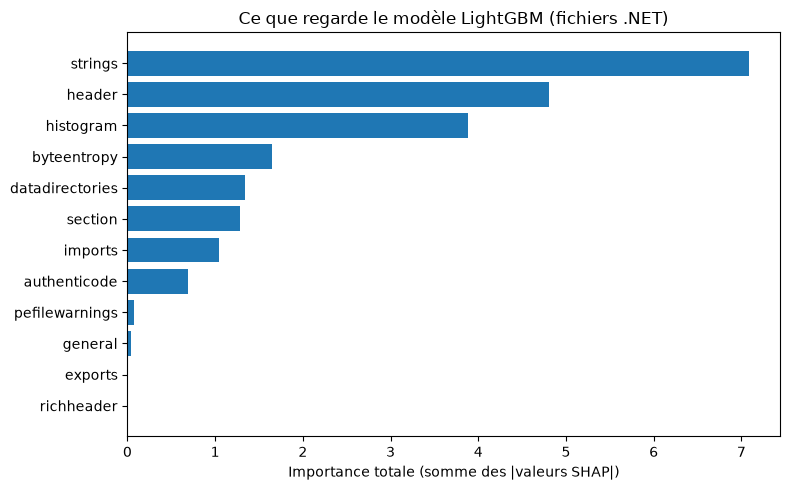


Modèle fichiers sauvegardé


In [11]:
import matplotlib.pyplot as plt, joblib

# 1. Valeurs SHAP calculées par LightGBM sur 2 000 fichiers de la validation
ech = X_val[:2000]
contrib = lgbm.booster_.predict(ech, pred_contrib=True)[:, :-1]   # dernière colonne = biais
imp = np.abs(contrib).mean(axis=0)

# 2. Additionner l'importance par groupe de features (dans l'ordre d'EMBER)
groupes, debut = {}, 0
for fe in thrember.PEFeatureExtractor().features:
    groupes[fe.name] = imp[debut:debut + fe.dim].sum()
    debut += fe.dim
groupes = pd.Series(groupes).sort_values()
print(groupes.sort_values(ascending=False).round(3))

plt.figure(figsize=(8, 5))
plt.barh(groupes.index, groupes.values)
plt.xlabel("Importance totale (somme des |valeurs SHAP|)")
plt.title("Ce que regarde le modèle LightGBM (fichiers .NET)")
plt.tight_layout()
plt.savefig(f"{MODELS}/shap_groupes_fichiers.png", dpi=150)
plt.show()

# 3. Sauvegarder le modèle, les seuils et les résultats
joblib.dump(lgbm, f"{MODELS}/files_lgbm.joblib")
infos_f = {"modele": "LightGBM sur features EMBER2024 (thrember), fichiers .NET",
           "seuil_suspect": 0.5, "seuil_dangereux": SEUIL_F, "nb_features": int(X_train.shape[1]),
           "donnees": "EMBER2024 Dot_Net, train sept. 2023 → sept. 2024, test sept. → déc. 2024"}
json.dump(infos_f, open(f"{MODELS}/files_infos.json", "w"), indent=2, ensure_ascii=False)
final_f.round(3).to_csv(f"{MODELS}/files_resultats_test.csv")
print("\nModèle fichiers sauvegardé")